# A4 · Evaluación de la Efectividad del Marketing
**Proyecto 01 — Retail Intelligence (RetailVenture C.A.)**

Preguntas del enunciado:
1. **Conversión** por tipo de campaña, canal de envío y segmento: ¿qué combinaciones rinden más?
2. **Efecto del descuento** ofrecido sobre la conversión, **controlando por segmento**.
3. **Segmento que recibe campañas y no convierte**, con hipótesis basadas en CRM y devoluciones.
4. **ROI por tipo de campaña**: monto de compra convertida vs. costo implícito del descuento.

Principio metodológico (igual que A3): cada diferencia se contrasta contra el azar (intervalos de Wilson, χ², corrección por comparaciones múltiples) y cada efecto se estima **con controles**. Antes de interpretar el descuento como causa se verifica **cómo se asignó**: si no depende del segmento, del tipo ni de la fecha, funciona como un experimento natural.

Supuestos heredados de A1 (§4, R19 y R21): `convertido` es la variable de conversión que reporta marketing, pero el 77,5 % de las conversiones **no** tiene compra registrada en 30 días; y el descuento ofrecido casi nunca coincide con el aplicado. Por eso el ROI se calcula con dos fuentes de monto (declarado y verificado) y con el descuento **ofrecido**.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportion_confint
from statsmodels.stats.multitest import multipletests
from scipy import stats
from pathlib import Path

pd.set_option('display.max_columns', 40); pd.set_option('display.width', 170)
CLEAN, FIG, TAB = Path('../data/clean'), Path('../outputs/figuras'), Path('../outputs/tablas')
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'text.parse_math': False})
ORDEN_SEG = ['Premium', 'Frecuente', 'Esporádico', 'Nuevo', 'Inactivo']
PALETA = {'Premium': '#2E4057', 'Frecuente': '#4C72B0', 'Esporádico': '#8DA0CB', 'Nuevo': '#55A868', 'Inactivo': '#C44E52'}
VENTANA = 90   # días de historia previa al envío para las hipótesis de CRM y devoluciones

camp = pd.read_csv(CLEAN / 'fact_campanas.csv', parse_dates=['fecha_envio'])
ventas = pd.read_csv(CLEAN / 'fact_ventas.csv', parse_dates=['fecha'])
clientes = pd.read_csv(CLEAN / 'dim_cliente.csv', parse_dates=['primera_compra', 'ultima_compra', 'fecha_alta_efectiva'])
crm = pd.read_csv(CLEAN / 'fact_interacciones.csv', parse_dates=['fecha'])
ventas['segmento'] = ventas.cliente_id.map(clientes.set_index('cliente_id').segmento)
camp['anio'] = camp.fecha_envio.dt.year
camp['t_anios'] = (camp.fecha_envio - pd.Timestamp('2023-01-01')).dt.days / 365
camp['desc_pct'] = (camp.descuento_ofrecido * 100).round().astype(int)

# El tipo de campaña determina el canal (cada tipo sale por un solo canal): se verifica antes de analizarlos por separado.
tipo_canal = pd.crosstab(camp.tipo_campana, camp.canal_campana)
assert ((tipo_canal > 0).sum(axis=1) == 1).all(), 'algún tipo de campaña sale por más de un canal'

# Punto de partida: volumen y embudo envío → apertura → conversión, por año (la premisa del caso).
def embudo(d):
    return pd.Series({'envíos': len(d), 'clientes': d.cliente_id.nunique(), 'tasa_apertura': d.abierto.mean(),
                      'conversión_s/envíos': d.convertido.mean(), 'conversión_s/abiertos': d.loc[d.abierto == 1, 'convertido'].mean(),
                      'conversión_verificada': d.flag_conversion_verificada.mean(), 'descuento_medio': d.descuento_ofrecido.mean()})
base = pd.concat({'2023': embudo(camp[camp.anio == 2023]), '2024': embudo(camp[camp.anio == 2024]), 'Total': embudo(camp)}, axis=1)
assert (camp.loc[camp.abierto == 0, 'convertido'] == 0).all()   # nadie convierte sin abrir: el embudo es coherente
base.to_csv(TAB / 'a4_embudo_anual.csv')
display(tipo_canal)
base.style.format('{:.1%}').format('{:,.0f}', subset=pd.IndexSlice[['envíos', 'clientes'], :])

canal_campana,email,push_app,redes_sociales,sms
tipo_campana,,,,
email_descuento,3099,0,0,0
email_fidelizacion,1748,0,0,0
push_reactivacion,0,1768,0,0
sms_oferta_flash,0,0,0,1345
social_ads,0,0,860,0


,2023,2024,Total
envíos,"4,368","4,452","8,820"
clientes,"3,190","3,211","4,800"
tasa_apertura,35.6%,36.3%,35.9%
conversión_s/envíos,11.2%,6.9%,9.0%
conversión_s/abiertos,31.6%,18.9%,25.1%
conversión_verificada,2.5%,1.6%,2.0%
descuento_medio,12.6%,12.3%,12.4%


**Lectura: la conversión sí cayó a casi la mitad, y la caída ocurre *después* de abrir la campaña.**

- 8.820 envíos a 4.800 clientes en 24 meses. Cada tipo de campaña sale por un único canal (`email_descuento` y `email_fidelizacion` por email, `push_reactivacion` por push, `sms_oferta_flash` por SMS y `social_ads` por redes). Por eso **tipo y canal no se pueden separar**: comparar canales es comparar tipos.
- Conversión sobre envíos: **11,2 % en 2023 → 6,9 % en 2024** (11,3 % en el 1T-2023 → 5,6 % en el 4T-2024). La premisa del caso (22 % → 11 %) se confirma en **proporción** (−50 %), no en nivel; el 22 % no aparece ni sobre campañas abiertas (31,6 % → 19,0 %).
- La **apertura no cambió** (35,6 % → 36,3 %) y el **descuento medio tampoco** (12,6 % → 12,3 %). Lo que se desplomó es la conversión de quien abre.
- Solo el **2,0 %** de los envíos tiene una conversión **verificada** (compra real en 30 días), frente al 9,0 % declarado. Toda cifra de ROI debe leerse con esa brecha en mente (A1, R19).

## 1. Conversión por tipo de campaña, canal y segmento

### 1.1 Tasas con intervalo de confianza y prueba de independencia

In [2]:
def tasas(d, dim):
    g = d.groupby(dim).agg(envíos=('campana_id', 'size'), aperturas=('abierto', 'sum'), conversiones=('convertido', 'sum'),
                           verificadas=('flag_conversion_verificada', 'sum'))
    g['tasa_apertura'] = g.aperturas / g.envíos
    g['conversión'] = g.conversiones / g.envíos
    g['ic95_inf'], g['ic95_sup'] = proportion_confint(g.conversiones, g.envíos, method='wilson')
    g['conv_s/abiertos'] = g.conversiones / g.aperturas
    g['conv_verificada'] = g.verificadas / g.envíos
    return g

filas, salida = [], {}
for dim in ['tipo_campana', 'canal_campana', 'segmento']:
    salida[dim] = tasas(camp, dim)
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(camp[dim], camp.convertido))
    filas.append({'dimensión': dim, 'chi2': chi2, 'gl': dof, 'p_valor': p,
                  'V_Cramer': np.sqrt(chi2 / len(camp)), 'rango_conversión': f"{salida[dim]['conversión'].min():.1%} – {salida[dim]['conversión'].max():.1%}"})
pruebas = pd.DataFrame(filas).set_index('dimensión'); pruebas.to_csv(TAB / 'a4_conversion_chi2.csv')
conv_dim = pd.concat(salida, names=['dimensión', 'nivel']); conv_dim.to_csv(TAB / 'a4_conversion_dimensiones.csv')
display(pruebas.style.format({'chi2': '{:.1f}', 'p_valor': '{:.2e}', 'V_Cramer': '{:.3f}'}))
fmt = {c: '{:.1%}' for c in ['tasa_apertura', 'conversión', 'ic95_inf', 'ic95_sup', 'conv_s/abiertos', 'conv_verificada']}
conv_dim.drop(columns=['aperturas', 'verificadas']).style.format(fmt)

,chi2,gl,p_valor,V_Cramer,rango_conversión
dimensión,,,,,
tipo_campana,2.9,4,5.75e-01,0.018,8.3% – 10.0%
canal_campana,1.2,3,7.50e-01,0.012,8.3% – 9.2%
segmento,49.0,4,5.93e-10,0.075,5.5% – 13.7%


**Lectura: el tipo de campaña y el canal no importan; el segmento sí.**

- **Tipo** (8,3 %–10,0 %, p = 0,58) y **canal** (8,3 %–9,2 %, p = 0,75): las diferencias caben en el azar, y todos los intervalos de confianza se solapan.
- **Segmento** (p < 10⁻⁹): Premium 13,7 %, Nuevo 10,6 %, Esporádico 9,5 %, Frecuente 8,0 % e **Inactivo 5,5 %**.
- La **apertura es igual en todos** (34 %–37 %). La diferencia entre segmentos aparece al decidir la compra: Premium convierte el 38 % de lo que abre e Inactivo, el 16 %.
- En conversión **verificada** la brecha es aún mayor: Premium 7,4 % e Inactivo 0,16 % (2 compras reales en 1.238 envíos).

### 1.2 Combinaciones tipo × segmento: ¿cuáles destacan más allá del azar?

,LR,gl,p_valor,celdas_significativas_FDR
segmento × tipo,11.5,16,0.776,0


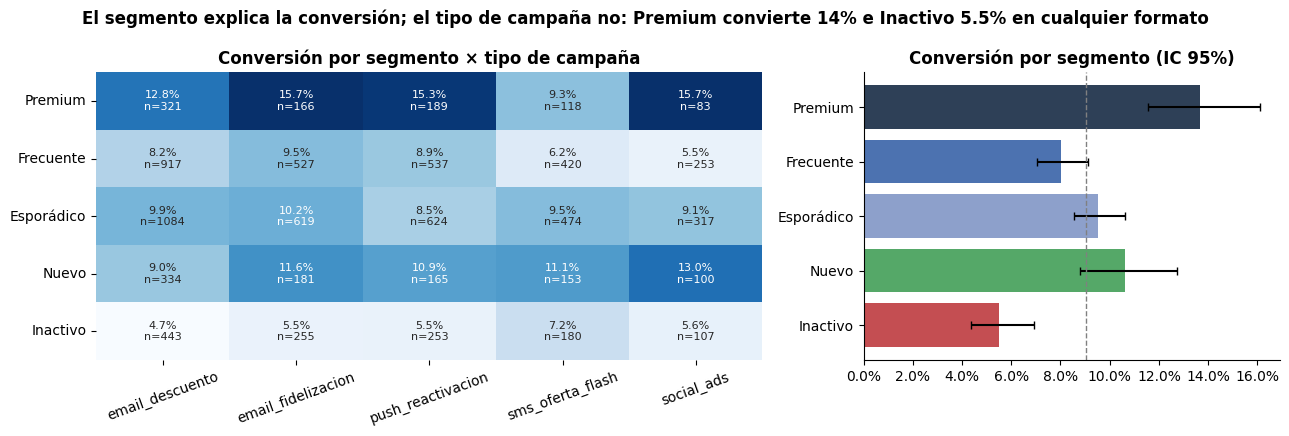

In [3]:
# Cada celda se contrasta con la conversión esperada para su segmento (la del segmento en todas las campañas):
# así se aísla si el *tipo* aporta algo para ese segmento o si la celda solo refleja quién la recibe.
comb = tasas(camp, ['segmento', 'tipo_campana']).reset_index()
p_seg = camp.groupby('segmento').convertido.mean()
comb['esperada_segmento'] = comb.segmento.map(p_seg)
comb['p_valor'] = [stats.binomtest(int(k), int(n), p).pvalue for k, n, p in zip(comb.conversiones, comb.envíos, comb.esperada_segmento)]
comb['p_FDR'] = multipletests(comb.p_valor, method='fdr_bh')[1]
comb['significativa_FDR'] = comb.p_FDR < 0.05
comb.to_csv(TAB / 'a4_conversion_tipo_segmento.csv', index=False)

# Prueba global de interacción: ¿el efecto del tipo cambia según el segmento? (razón de verosimilitud)
m_ad = smf.logit('convertido ~ C(segmento) + C(tipo_campana)', data=camp).fit(disp=0)
m_int = smf.logit('convertido ~ C(segmento) * C(tipo_campana)', data=camp).fit(disp=0)
lr = 2 * (m_int.llf - m_ad.llf); gl = m_int.df_model - m_ad.df_model
interaccion = pd.DataFrame({'LR': [lr], 'gl': [gl], 'p_valor': [stats.chi2.sf(lr, gl)], 'celdas_significativas_FDR': [comb.significativa_FDR.sum()]},
                           index=['segmento × tipo'])
display(interaccion.style.format({'LR': '{:.1f}', 'gl': '{:.0f}', 'p_valor': '{:.3f}'}))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={'width_ratios': [1.6, 1]})
mat = comb.pivot(index='segmento', columns='tipo_campana', values='conversión').loc[ORDEN_SEG]
n_mat = comb.pivot(index='segmento', columns='tipo_campana', values='envíos').loc[ORDEN_SEG]
sns.heatmap(mat * 100, annot=(mat * 100).round(1).astype(str) + '%\nn=' + n_mat.astype(str), fmt='', cmap='Blues', cbar=False, ax=axes[0], annot_kws={'fontsize': 8})
axes[0].set(xlabel='', ylabel='', title='Conversión por segmento × tipo de campaña'); axes[0].tick_params(axis='x', rotation=20)
s = salida['segmento'].loc[ORDEN_SEG]
axes[1].barh(s.index, s['conversión'], xerr=[s['conversión'] - s.ic95_inf, s.ic95_sup - s['conversión']], color=[PALETA[k] for k in s.index], capsize=3)
axes[1].axvline(camp.convertido.mean(), ls='--', c='grey', lw=1); axes[1].invert_yaxis()
axes[1].xaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set_title('Conversión por segmento (IC 95%)')
fig.suptitle(f"El segmento explica la conversión; el tipo de campaña no: Premium convierte {s.loc['Premium','conversión']:.0%} e Inactivo {s.loc['Inactivo','conversión']:.1%} en cualquier formato",
             fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a4_conversion_segmento_tipo.png', dpi=150); plt.show()

**Lectura: no existe una "combinación ganadora"; el retorno lo define *a quién* se envía, no *qué* se envía.**

- La interacción segmento × tipo **no es significativa** (LR = 11,5, 16 gl, p = 0,78), y **ninguna de las 25 celdas** se aparta de la tasa de su segmento tras la corrección FDR.
- Las celdas más altas (Premium × fidelización o social ads, 15,7 %) y las más bajas (Inactivo × email de descuento, 4,7 %) solo reflejan **el segmento que las recibe**.
- **Implicación:** optimizar el formato o el canal no va a mover la conversión. La palanca es la **selección de destinatarios** y la **oferta** (sección 2).

### 1.3 ¿Por qué cayó la conversión? Descomposición del embudo en el tiempo

In [4]:
# Tres explicaciones candidatas para la caída 2023 → 2024: (a) se abre menos, (b) cambió la mezcla
# (más envíos a segmentos que convierten poco o con menos descuento), (c) quien abre compra menos.
trim = camp.groupby(camp.fecha_envio.dt.to_period('Q')).agg(envíos=('campana_id', 'size'), apertura=('abierto', 'mean'),
                                                           conversión=('convertido', 'mean'), descuento_medio=('descuento_ofrecido', 'mean'))
trim['conv_s/abiertos'] = camp[camp.abierto == 1].groupby(camp.fecha_envio.dt.to_period('Q')).convertido.mean()
trim.index = trim.index.astype(str); trim.to_csv(TAB / 'a4_conversion_trimestral.csv')

# (b) Mezcla: si la caída fuera de composición, desaparecería al controlar segmento, tipo y descuento.
m_t0 = smf.logit('convertido ~ t_anios', data=camp).fit(disp=0)
m_t1 = smf.logit('convertido ~ t_anios + C(segmento) + C(tipo_campana) + descuento_ofrecido', data=camp).fit(disp=0)
m_ab = smf.logit('abierto ~ t_anios + C(segmento) + C(tipo_campana) + descuento_ofrecido', data=camp).fit(disp=0)
m_ca = smf.logit('convertido ~ t_anios + C(segmento) + C(tipo_campana) + descuento_ofrecido', data=camp[camp.abierto == 1]).fit(disp=0)
tend = pd.DataFrame({'odds_ratio_por_año': [np.exp(m.params['t_anios']) for m in (m_t0, m_t1, m_ab, m_ca)],
                     'p_valor': [m.pvalues['t_anios'] for m in (m_t0, m_t1, m_ab, m_ca)]},
                    index=['Conversión (sin controles)', 'Conversión (controlando mezcla)', 'Apertura (controlando mezcla)', 'Conversión | abrió (controlando mezcla)'])
tend.to_csv(TAB / 'a4_tendencia_embudo.csv')
display(tend.style.format({'odds_ratio_por_año': '{:.2f}', 'p_valor': '{:.2e}'}))
trim.style.format({'envíos': '{:,.0f}', 'apertura': '{:.1%}', 'conversión': '{:.1%}', 'descuento_medio': '{:.1%}', 'conv_s/abiertos': '{:.1%}'})

,odds_ratio_por_año,p_valor
Conversión (sin controles),0.63,7.84e-13
Conversión (controlando mezcla),0.63,5.30e-12
Apertura (controlando mezcla),0.98,6.34e-01
Conversión | abrió (controlando mezcla),0.59,6.97e-13


,envíos,apertura,conversión,descuento_medio,conv_s/abiertos
fecha_envio,,,,,
2023Q1,"1,055",37.8%,11.3%,12.8%,29.8%
2023Q2,"1,113",37.1%,12.3%,12.6%,33.2%
2023Q3,"1,094",34.3%,11.2%,12.8%,32.5%
2023Q4,"1,106",33.2%,10.2%,12.2%,30.8%
2024Q1,"1,082",38.5%,7.9%,12.4%,20.6%
2024Q2,"1,128",33.7%,6.8%,12.3%,20.3%
2024Q3,"1,167",36.7%,7.1%,12.1%,19.4%
2024Q4,"1,075",36.3%,5.6%,12.3%,15.4%


**Lectura: la caída no es de mezcla ni de alcance; es de respuesta a la oferta.**

- Sin controles, las odds de convertir caen un **37 % por año** (OR = 0,63). **Controlando** segmento, tipo y descuento, la caída es la misma (OR = 0,63): no se explica por enviar más a segmentos malos ni por dar menos descuento.
- La **apertura no tiene tendencia** (OR = 0,98, p = 0,63). Toda la caída está en la **conversión de quien abre** (OR = 0,59).
- El quiebre es un **escalón al inicio de 2024** (30–33 % de conversión sobre abiertos en 2023 → ~20 % en 2024 y 15 % en el 4T), no un deterioro gradual.
- **Lo que los datos no permiten afirmar:** la causa del escalón. Los candidatos son cambios en la oferta, el precio relativo frente a la competencia o el proceso de compra. No hay variables de esto en los datasets, y A2 descartó la estacionalidad y la caída de ventas totales (planas en ~$725K/mes). **La conversión declarada cae, pero las ventas no**, lo que refuerza que la métrica de conversión de marketing no mide ventas (A1, R19).

## 2. Efecto del descuento ofrecido sobre la conversión, controlando por segmento

### 2.1 ¿Cómo se asignó el descuento? (condición para leerlo como causa)

In [5]:
# Si el descuento se hubiera dado más a quien ya iba a comprar (p. ej., Premium), su efecto estaría sesgado.
# Se prueba su independencia respecto de todo lo observable antes del envío.
bal = []
for dim in ['segmento', 'tipo_campana', 'anio']:
    chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(camp[dim], camp.desc_pct))
    bal.append({'variable': dim, 'chi2': chi2, 'gl': dof, 'p_valor': p, 'V_Cramer': np.sqrt(chi2 / (len(camp) * (min(camp[dim].nunique(), 6) - 1)))})
hist = ventas.groupby('cliente_id').agg(compras_hist=('transaccion_id', 'size'), gasto_hist=('monto_neto', 'sum'))
camp_h = camp.join(hist, on='cliente_id').fillna({'compras_hist': 0, 'gasto_hist': 0})
for v in ['compras_hist', 'gasto_hist']:
    h, p = stats.kruskal(*[g[v] for _, g in camp_h.groupby('desc_pct')])
    bal.append({'variable': v + ' (Kruskal-Wallis)', 'chi2': h, 'gl': 5, 'p_valor': p, 'V_Cramer': np.nan})
balance = pd.DataFrame(bal).set_index('variable'); balance.to_csv(TAB / 'a4_descuento_balance.csv')
balance.style.format({'chi2': '{:.1f}', 'p_valor': '{:.3f}', 'V_Cramer': '{:.3f}'})

,chi2,gl,p_valor,V_Cramer
variable,,,,
segmento,20.0,20,0.460,0.024
tipo_campana,25.2,20,0.192,0.027
anio,3.8,5,0.582,0.021
compras_hist (Kruskal-Wallis),1.8,5,0.875,nan
gasto_hist (Kruskal-Wallis),2.7,5,0.748,nan


**Lectura: el descuento se asignó como si fuera al azar, así que su efecto se puede leer como causal.**

- El nivel de descuento (0 %–25 %) es **independiente** del segmento (p = 0,46), del tipo de campaña (p = 0,19), del año (p = 0,58) y de la historia de compras y de gasto del cliente (p = 0,88 y 0,75). Todos los V de Cramér son < 0,03.
- Es decir, nadie eligió dar más descuento a quien ya iba a comprar. Eso convierte los datos en un **experimento natural**. A diferencia de A2 (descuentos en transacciones, observacional), aquí la comparación entre niveles de descuento **no está sesgada por selección**.

### 2.2 Estimación del efecto con controles

In [6]:
# (1) Tasas por nivel de descuento dentro de cada segmento (estratificación directa).
estr = pd.crosstab(camp.segmento, camp.desc_pct, values=camp.convertido, aggfunc='mean').loc[ORDEN_SEG]
estr.to_csv(TAB / 'a4_conversion_descuento_segmento.csv')

# (2) Regresión logística: descuento + efectos fijos de segmento (pedido por el enunciado), luego + tipo y tiempo.
especs = {'Sin controles': 'convertido ~ descuento_ofrecido',
          '+ segmento': 'convertido ~ descuento_ofrecido + C(segmento)',
          '+ segmento + tipo + tiempo': 'convertido ~ descuento_ofrecido + C(segmento) + C(tipo_campana) + t_anios'}
filas = []
for nombre, f in especs.items():
    m = smf.logit(f, data=camp).fit(disp=0)
    ame = m.get_margeff(at='overall').summary_frame().loc['descuento_ofrecido']
    filas.append({'modelo': nombre, 'OR_por_+5pp': np.exp(m.params['descuento_ofrecido'] * 0.05), 'p_valor': m.pvalues['descuento_ofrecido'],
                  'efecto_marginal_+5pp': ame['dy/dx'] * 0.05, 'ic95_inf': ame['Conf. Int. Low'] * 0.05, 'ic95_sup': ame['Cont. Int. Hi.'] * 0.05})
m_full = m
# (3) ¿El efecto difiere entre segmentos? Interacción descuento × segmento (prueba de razón de verosimilitud).
m_ds = smf.logit('convertido ~ descuento_ofrecido * C(segmento) + C(tipo_campana) + t_anios', data=camp).fit(disp=0)
lr = 2 * (m_ds.llf - m_full.llf); gl = m_ds.df_model - m_full.df_model
# (4) Mecanismo: ¿el descuento hace abrir más o hace comprar más a quien abre?
m_open = smf.logit('abierto ~ descuento_ofrecido + C(segmento) + C(tipo_campana) + t_anios', data=camp).fit(disp=0)
m_cond = smf.logit('convertido ~ descuento_ofrecido + C(segmento) + C(tipo_campana) + t_anios', data=camp[camp.abierto == 1]).fit(disp=0)
# (5) Robustez: ¿el efecto se ve también en la compra real (conversión verificada en 30 días)?
m_ver = smf.logit('flag_conversion_verificada ~ descuento_ofrecido + C(segmento) + C(tipo_campana) + t_anios', data=camp).fit(disp=0)
for nombre, m in [('Mecanismo: apertura', m_open), ('Mecanismo: conversión | abrió', m_cond), ('Robustez: conversión verificada', m_ver)]:
    filas.append({'modelo': nombre, 'OR_por_+5pp': np.exp(m.params['descuento_ofrecido'] * 0.05), 'p_valor': m.pvalues['descuento_ofrecido']})
efecto = pd.DataFrame(filas).set_index('modelo'); efecto.to_csv(TAB / 'a4_efecto_descuento.csv')
display(efecto.style.format({'OR_por_+5pp': '{:.3f}', 'p_valor': '{:.2e}', 'efecto_marginal_+5pp': '{:+.2%}', 'ic95_inf': '{:+.2%}', 'ic95_sup': '{:+.2%}'}, na_rep='—'))
display(pd.DataFrame({'LR': [lr], 'gl': [gl], 'p_valor': [stats.chi2.sf(lr, gl)]}, index=['descuento × segmento']).style.format({'LR': '{:.1f}', 'gl': '{:.0f}', 'p_valor': '{:.3f}'}))

# (6) Forma de la curva: ¿hay rendimientos decrecientes? Descuento como categoría (referencia 0%).
m_cat = smf.logit('convertido ~ C(desc_pct) + C(segmento) + C(tipo_campana) + t_anios', data=camp).fit(disp=0)
pred = pd.DataFrame({d: m_cat.predict(camp.assign(desc_pct=d)).mean() for d in sorted(camp.desc_pct.unique())}, index=['conversión_ajustada']).T
pred['incremento_vs_0%'] = pred.conversión_ajustada - pred.conversión_ajustada.iloc[0]
pred['incremento_marginal'] = pred.conversión_ajustada.diff()
pred.index.name = 'descuento_%'; pred.to_csv(TAB / 'a4_curva_descuento.csv')
display(pred.style.format('{:+.2%}').format('{:.2%}', subset=['conversión_ajustada']))
(estr * 100).round(1)

,OR_por_+5pp,p_valor,efecto_marginal_+5pp,ic95_inf,ic95_sup
modelo,,,,,
Sin controles,1.179,1.16e-13,+1.34%,+0.99%,+1.70%
+ segmento,1.179,1.40e-13,+1.34%,+0.98%,+1.70%
+ segmento + tipo + tiempo,1.175,4.92e-13,+1.30%,+0.95%,+1.66%
Mecanismo: apertura,1.010,4.56e-01,—,—,—
Mecanismo: conversión | abrió,1.217,1.19e-14,—,—,—
Robustez: conversión verificada,1.135,5.48e-03,—,—,—


,LR,gl,p_valor
descuento × segmento,6.7,4,0.154


,conversión_ajustada,incremento_vs_0%,incremento_marginal
descuento_%,,,
0,5.22%,+0.00%,+nan%
5,6.92%,+1.70%,+1.70%
10,8.86%,+3.63%,+1.94%
15,10.61%,+5.38%,+1.75%
20,11.35%,+6.12%,+0.74%
25,11.28%,+6.06%,-0.07%


desc_pct,0,5,10,15,20,25
segmento,,,,,,
Premium,10.6,11.7,8.6,15.7,18.8,16.5
Frecuente,3.7,5.9,8.4,10.0,9.6,11.0
Esporádico,5.9,7.2,10.2,11.7,12.0,10.4
Nuevo,7.3,10.5,8.9,12.0,10.3,15.2
Inactivo,1.5,2.0,6.6,4.8,9.4,8.6


**Lectura: el descuento sí aumenta la conversión, con un efecto estable, igual en todos los segmentos y con techo en el 15–20 %.**

- **Cada +5 puntos de descuento suben la conversión +1,3 pp** (OR = 1,18; IC 95 %: +0,9 a +1,7 pp; p < 10⁻¹²). El estimado **no cambia** al controlar por segmento ni al agregar tipo y tiempo, lo esperado si la asignación es aleatoria (sección 2.1).
- **Mecanismo:** el descuento **no** hace abrir más (OR = 1,01, p = 0,46), pero sí hace **comprar** a quien abre (OR = 1,22). Actúa en la decisión de compra, como debe.
- **Robustez:** el efecto también aparece en la conversión **verificada** (OR = 1,14, p = 0,005). No es solo un artefacto del flag `convertido`.
- **Controlando por segmento** (lo que pide el enunciado), el efecto es **homogéneo**: la interacción descuento × segmento no es significativa (p = 0,15). Inactivo es el que más se mueve en términos relativos (1,5 % sin descuento → ~9 % con 20 %), pero desde una base muy baja.
- **Curva ajustada:** 0 % → 5,2 %, 5 % → 6,9 %, 10 % → 8,9 %, 15 % → 10,6 %, 20 % → 11,3 % y 25 % → 11,3 %. **Rendimientos decrecientes**: pasar de 20 % a 25 % no agrega conversión.
- **Diferencia con A2:** allí el descuento aplicado en la caja no generaba volumen. Aquí la *oferta* de campaña sí atrae compradores. Las dos conclusiones son compatibles: el descuento puede servir para **activar**, pero no como rebaja generalizada. Que convenga económicamente depende de su costo (sección 4).

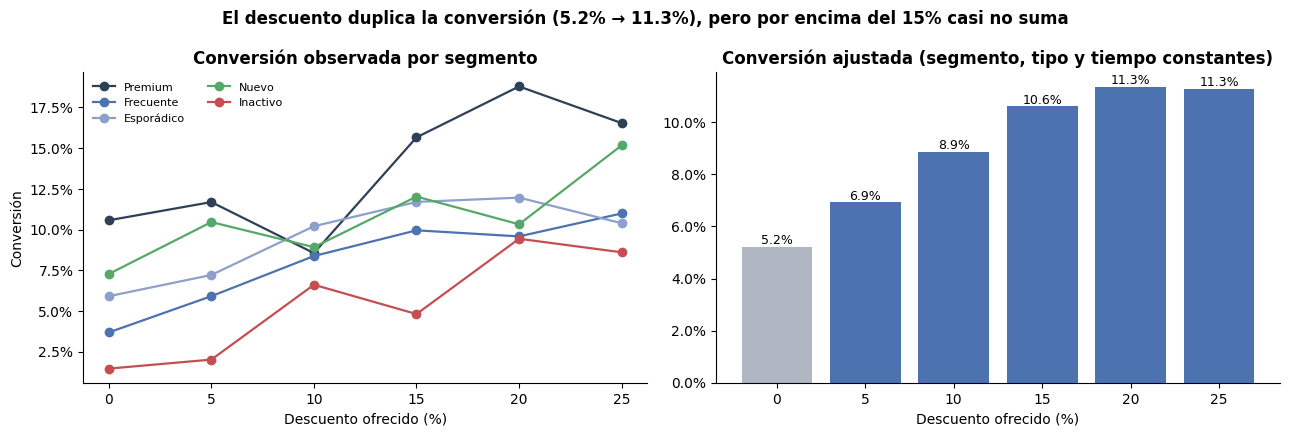

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
for sgm in ORDEN_SEG:
    axes[0].plot(estr.columns, estr.loc[sgm], marker='o', color=PALETA[sgm], label=sgm, lw=1.6)
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].set(xlabel='Descuento ofrecido (%)', ylabel='Conversión', title='Conversión observada por segmento')
axes[0].legend(frameon=False, fontsize=8, ncol=2)
axes[1].bar(pred.index.astype(str), pred.conversión_ajustada, color=['#B0B7C3'] + ['#4C72B0'] * (len(pred) - 1))
for i, v in enumerate(pred.conversión_ajustada):
    axes[1].text(i, v, f'{v:.1%}', ha='center', va='bottom', fontsize=9)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].set(xlabel='Descuento ofrecido (%)', title='Conversión ajustada (segmento, tipo y tiempo constantes)')
fig.suptitle(f"El descuento duplica la conversión ({pred.conversión_ajustada.iloc[0]:.1%} → {pred.conversión_ajustada.max():.1%}), pero por encima del 15% casi no suma",
             fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a4_efecto_descuento.png', dpi=150); plt.show()

## 3. El segmento que recibe campañas y no convierte

In [8]:
# Para cada envío se mira la historia del cliente en los VENTANA días previos (solo información disponible
# al momento de enviar, para no usar el futuro): quejas, quejas no resueltas, devoluciones, compras y recencia.
def historia_previa(envios):
    e = envios[['campana_id', 'cliente_id', 'fecha_envio']]
    def contar(eventos, col_fecha, nombre, filtro=None):
        ev = eventos if filtro is None else eventos[filtro]
        m = e.merge(ev[['cliente_id', col_fecha]], on='cliente_id')
        m = m[(m[col_fecha] < m.fecha_envio) & (m[col_fecha] >= m.fecha_envio - pd.Timedelta(days=VENTANA))]
        return m.groupby('campana_id').size().rename(nombre)
    dev = ventas.loc[ventas.flag_devuelta == 1, ['cliente_id', 'fecha']]
    partes = [contar(crm, 'fecha', 'quejas', crm.tipo == 'queja'),
              contar(crm, 'fecha', 'quejas_no_resueltas', (crm.tipo == 'queja') & (crm.flag_no_resuelta == 1)),
              contar(crm, 'fecha', 'contactos_crm', crm.tipo != 'felicitacion'),
              contar(dev, 'fecha', 'devoluciones'),
              contar(ventas, 'fecha', 'compras')]
    out = envios.set_index('campana_id').join(partes).fillna({p.name: 0 for p in partes})
    # Recencia: días desde la última compra antes del envío (sin compra previa = sin dato).
    ult = e.merge(ventas[['cliente_id', 'fecha']], on='cliente_id')
    ult = ult[ult.fecha < ult.fecha_envio].groupby('campana_id').fecha.max()
    out['dias_desde_compra'] = (out.fecha_envio - ult.reindex(out.index)).dt.days
    out['sin_compra_previa'] = out.dias_desde_compra.isna().astype(int)
    for c in ['quejas', 'quejas_no_resueltas', 'devoluciones', 'contactos_crm']:
        out['tuvo_' + c] = (out[c] > 0).astype(int)
    return out.reset_index()

hp = historia_previa(camp)
perfil = hp.groupby('segmento').agg(envíos=('campana_id', 'size'), conversión=('convertido', 'mean'), apertura=('abierto', 'mean'),
                                    conv_s_abiertos=('convertido', lambda s: s[hp.loc[s.index, 'abierto'] == 1].mean()),
                                    tuvo_queja=('tuvo_quejas', 'mean'), tuvo_queja_no_resuelta=('tuvo_quejas_no_resueltas', 'mean'),
                                    tuvo_devolución=('tuvo_devoluciones', 'mean'), compras_previas_90d=('compras', 'mean'),
                                    mediana_días_desde_compra=('dias_desde_compra', 'median'), sin_compra_previa=('sin_compra_previa', 'mean'),
                                    descuento_medio=('descuento_ofrecido', 'mean')).loc[ORDEN_SEG]
perfil.to_csv(TAB / 'a4_perfil_no_conversores.csv')
pct = ['conversión', 'apertura', 'conv_s_abiertos', 'tuvo_queja', 'tuvo_queja_no_resuelta', 'tuvo_devolución', 'sin_compra_previa', 'descuento_medio']
perfil.style.format({c: '{:.1%}' for c in pct}).format({'envíos': '{:,.0f}', 'compras_previas_90d': '{:.2f}', 'mediana_días_desde_compra': '{:.0f}'})

,envíos,conversión,apertura,conv_s_abiertos,tuvo_queja,tuvo_queja_no_resuelta,tuvo_devolución,compras_previas_90d,mediana_días_desde_compra,sin_compra_previa,descuento_medio
segmento,,,,,,,,,,,
Premium,877,0.136830,0.360319,0.379747,0.042189,0.027366,0.224629,2.19,24,0.070696,0.126397
Frecuente,"2,654",0.080256,0.357197,0.224684,0.029390,0.017709,0.148078,1.23,44,0.101356,0.123775
Esporádico,"3,118",0.095253,0.372033,0.256034,0.025657,0.016357,0.043618,0.32,124,0.288326,0.125000
Nuevo,933,0.106109,0.337621,0.314286,0.025723,0.019293,0.012862,0.15,168,0.534834,0.122508
Inactivo,"1,238",0.054927,0.347334,0.158140,0.025848,0.012116,0.016963,0.09,208,0.606624,0.123384


**Lectura: Inactivo es el segmento que recibe campañas y no convierte, y su perfil no es el de un cliente insatisfecho.**

- Inactivo recibe **1.238 envíos** (14 %) y convierte el **5,5 %**, la mitad que el resto. **Abre igual** (34,7 %), pero compra mucho menos cuando abre (15,8 % vs. 26,6 %).
- **No tiene más quejas** (2,6 % con una queja en los 90 días previos, igual que el resto) ni más quejas sin resolver (1,2 %).
- **Devuelve menos, no más** (1,7 % vs. 9,7 %), simplemente porque casi no compra.
- Lo que sí lo distingue es la **desconexión**: el **61 %** no tiene ninguna compra antes del envío (vs. 23 % del resto) y la mediana de días desde su última compra es **208** (Premium: 24).

### 3.1 Contraste de hipótesis: ¿qué explica que no conviertan?

In [9]:
# H1 Insatisfacción: una queja (o queja no resuelta) reciente reduce la conversión.
# H2 Mala experiencia de producto: una devolución reciente reduce la conversión.
# H3 Desconexión: el cliente ya no compra (recencia alta o sin compras previas) y la campaña no lo reactiva.
# H4 Saturación/canal: el segmento no abre (falla de alcance) vs. abre y no compra (falla de oferta).
# Cada hipótesis se prueba en toda la base con controles (segmento, tipo, descuento, tiempo), y luego dentro de Inactivo.
hp['log_dias'] = np.log1p(hp.dias_desde_compra.fillna(hp.dias_desde_compra.max()))
ctrl = 'C(segmento) + C(tipo_campana) + descuento_ofrecido + t_anios'
hips = {'H1 queja reciente': 'tuvo_quejas', 'H1b queja no resuelta reciente': 'tuvo_quejas_no_resueltas',
        'H2 devolución reciente': 'tuvo_devoluciones', 'H3 recencia (log días)': 'log_dias', 'H3b sin compra previa': 'sin_compra_previa'}
filas = []
for nombre, var in hips.items():
    m = smf.logit(f'convertido ~ {var} + {ctrl}', data=hp).fit(disp=0)
    sub = hp[hp.segmento == 'Inactivo']
    mi = smf.logit(f'convertido ~ {var} + C(tipo_campana) + descuento_ofrecido + t_anios', data=sub).fit(disp=0) if sub[var].nunique() > 1 else None
    filas.append({'hipótesis': nombre, 'OR_total': np.exp(m.params[var]), 'p_total': m.pvalues[var],
                  'OR_Inactivo': np.exp(mi.params[var]) if mi is not None else np.nan, 'p_Inactivo': mi.pvalues[var] if mi is not None else np.nan,
                  'prevalencia_Inactivo': sub[var].mean() if var.startswith(('tuvo', 'sin')) else np.nan,
                  'prevalencia_resto': hp.loc[hp.segmento != 'Inactivo', var].mean() if var.startswith(('tuvo', 'sin')) else np.nan})
hipotesis = pd.DataFrame(filas).set_index('hipótesis')
hipotesis['p_total_FDR'] = multipletests(hipotesis.p_total, method='fdr_bh')[1]
hipotesis.to_csv(TAB / 'a4_hipotesis_no_conversion.csv')

# H4: ¿la brecha de Inactivo está en la apertura o después? Se descompone su conversión contra el resto.
ina, resto = hp[hp.segmento == 'Inactivo'], hp[hp.segmento != 'Inactivo']
h4 = pd.DataFrame({'Inactivo': [ina.abierto.mean(), ina.loc[ina.abierto == 1, 'convertido'].mean(), ina.convertido.mean()],
                   'Resto': [resto.abierto.mean(), resto.loc[resto.abierto == 1, 'convertido'].mean(), resto.convertido.mean()]},
                  index=['apertura', 'conversión | abrió', 'conversión'])
h4['razón Inactivo/Resto'] = h4.Inactivo / h4.Resto
h4.to_csv(TAB / 'a4_inactivo_embudo.csv')
display(h4.style.format('{:.1%}').format('{:.2f}', subset=['razón Inactivo/Resto']))
hipotesis.style.format({'OR_total': '{:.2f}', 'p_total': '{:.3f}', 'OR_Inactivo': '{:.2f}', 'p_Inactivo': '{:.3f}', 'p_total_FDR': '{:.3f}',
                        'prevalencia_Inactivo': '{:.1%}', 'prevalencia_resto': '{:.1%}'}, na_rep='—')

,Inactivo,Resto,razón Inactivo/Resto
apertura,34.7%,36.1%,0.96
conversión | abrió,15.8%,26.6%,0.59
conversión,5.5%,9.6%,0.57


,OR_total,p_total,OR_Inactivo,p_Inactivo,prevalencia_Inactivo,prevalencia_resto,p_total_FDR
hipótesis,,,,,,,
H1 queja reciente,1.15,0.520,0.72,0.755,2.6%,2.9%,0.983
H1b queja no resuelta reciente,0.88,0.666,2.05,0.496,1.2%,1.8%,0.983
H2 devolución reciente,1.00,0.986,0.94,0.955,1.7%,9.7%,0.986
H3 recencia (log días),0.99,0.786,0.90,0.417,—,—,0.983
H3b sin compra previa,0.93,0.505,1.04,0.889,60.7%,22.8%,0.983


**Lectura: ni el CRM ni las devoluciones explican la no conversión. Las hipótesis de insatisfacción se rechazan.**

| Hipótesis | Resultado (controlando segmento, tipo, descuento y tiempo) |
|---|---|
| **H1** Queja reciente / queja no resuelta | Sin efecto (OR 1,15 y 0,88; p ≥ 0,52). Tampoco dentro de Inactivo |
| **H2** Devolución reciente | Sin efecto (OR = 1,00; p = 0,99) |
| **H3** Recencia / sin compras previas | Sin efecto **una vez que se controla el segmento** (p ≥ 0,50) |
| **H4** Falla de alcance vs. de oferta | Inactivo abre al 96 % del resto, pero convierte al 59 % de lo que abre: **es una falla de oferta/intención, no de alcance** |

- **Interpretación:** Inactivo no deja de comprar por una mala experiencia registrada (quejas o devoluciones). Es un cliente de **baja intención**, que la etiqueta de segmento captura mejor que cualquier evento reciente. Esto es coherente con A3: los clientes compran a un ritmo propio y "sin memoria", y la recencia no predice la fuga.
- **Hipótesis que quedan abiertas** (sin datos para probarlas): una oferta poco relevante para su historial, la competencia en precio, o que la etiqueta "Inactivo" agrupe registros que nunca fueron clientes activos (61 % sin compras previas).
- **Cautela:** las pruebas tienen poca potencia para eventos raros (solo el 2,6 % de los envíos a Inactivo tiene una queja previa). Un efecto pequeño no se puede descartar, pero sí uno que explique la brecha de 4 puntos.

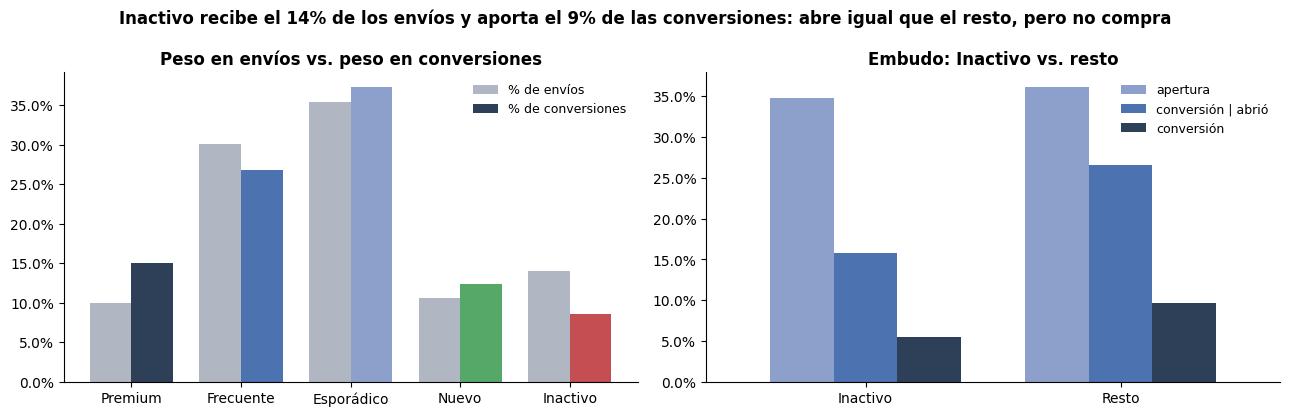

,envíos,conversiones,%_envíos,%_conversiones,envíos_por_conversión
segmento,,,,,
Premium,877,120,9.9%,15.1%,7.3
Frecuente,2654,213,30.1%,26.7%,12.5
Esporádico,3118,297,35.4%,37.3%,10.5
Nuevo,933,99,10.6%,12.4%,9.4
Inactivo,1238,68,14.0%,8.5%,18.2


In [10]:
# Recursos que hoy se dirigen a quien no convierte: envíos y descuento comprometido por segmento.
desp = hp.groupby('segmento').agg(envíos=('campana_id', 'size'), conversiones=('convertido', 'sum')).loc[ORDEN_SEG]
desp['%_envíos'] = desp.envíos / desp.envíos.sum()
desp['%_conversiones'] = desp.conversiones / desp.conversiones.sum()
desp['envíos_por_conversión'] = desp.envíos / desp.conversiones
desp.to_csv(TAB / 'a4_envios_por_conversion.csv')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
x = np.arange(len(desp)); w = 0.38
axes[0].bar(x - w/2, desp['%_envíos'], w, color='#B0B7C3', label='% de envíos')
axes[0].bar(x + w/2, desp['%_conversiones'], w, color=[PALETA[k] for k in desp.index], label='% de conversiones')
axes[0].set_xticks(x, desp.index); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[0].legend(frameon=False, fontsize=9)
axes[0].set_title('Peso en envíos vs. peso en conversiones')
emb = h4[['Inactivo', 'Resto']].T
emb.plot.bar(ax=axes[1], color=['#8DA0CB', '#4C72B0', '#2E4057'], rot=0, width=0.75)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1)); axes[1].legend(frameon=False, fontsize=9); axes[1].set_title('Embudo: Inactivo vs. resto')
fig.suptitle(f"Inactivo recibe el {desp.loc['Inactivo','%_envíos']:.0%} de los envíos y aporta el {desp.loc['Inactivo','%_conversiones']:.0%} de las conversiones: "
             f"abre igual que el resto, pero no compra", fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a4_segmento_no_convierte.png', dpi=150); plt.show()
desp.style.format({'%_envíos': '{:.1%}', '%_conversiones': '{:.1%}', 'envíos_por_conversión': '{:.1f}'})

**Lectura: cada conversión de Inactivo cuesta 2,5 veces más envíos que una de Premium.**

- Inactivo concentra el **14 %** de los envíos y solo el **8,5 %** de las conversiones: **18 envíos por conversión**, frente a 7 en Premium y 10–12 en el resto. Y de sus 68 conversiones declaradas, solo **2** se reflejan en ventas.
- Premium es el caso opuesto: 10 % de los envíos y 15 % de las conversiones. Está **sub-contactado** respecto de su respuesta.
- **Implicación para A5:** reasignar frecuencia de contacto de Inactivo hacia Premium y Nuevo, este último por el problema de activación detectado en A3: el 61 % de los Nuevos nunca repite.

## 4. ROI por tipo de campaña

El enunciado pide comparar el **monto de compra convertida** con el **costo implícito del descuento ofrecido**. Hay dos obstáculos documentados en A1 que obligan a declarar supuestos:

- **Monto convertido.** Solo el 22,5 % de las conversiones tiene una compra en los 30 días siguientes. Se calculan dos versiones: **declarado** (toda conversión vale el ticket bruto promedio del segmento del cliente, que es lo que marketing reportaría) y **verificado** (solo el monto realmente comprado en 30 días, `monto_compra_30d`, de los envíos convertidos).
- **Costo del descuento.** Se usa el descuento **ofrecido** sobre el precio de lista de la compra convertida: costo = d / (1 − d) × monto pagado. No hay datos de costo de envío, así que el ROI es **bruto de costos de operación** (cota superior).

Fórmulas: `ROI_ventas = (monto convertido − costo descuento) / costo descuento` (la que pide el enunciado) y `ROI_margen = (margen de la compra − costo descuento) / costo descuento`, más estricta porque el descuento se paga con margen, no con ventas. Finalmente, un **ROI incremental**: solo cuenta la conversión **causada** por el descuento (sección 2) y carga como costo el descuento regalado a quien habría comprado igual.

In [11]:
# Ticket y margen de referencia por segmento (precio de lista, antes de descuento, y margen bruto antes de descuento).
ref = ventas.groupby('segmento').agg(ticket_lista=('ingreso_bruto', 'mean'), margen_lista=('margen_bruto', 'mean'),
                                     descuento_monto=('descuento_monto', 'mean'))
ref['margen_lista'] += ref.descuento_monto   # margen antes de aplicar cualquier descuento
camp_r = camp.join(ref[['ticket_lista', 'margen_lista']], on='segmento')
d = camp_r.descuento_ofrecido
conv = camp_r.convertido == 1

# Declarado: cada conversión = ticket de lista del segmento, pagado con el descuento ofrecido.
camp_r['venta_decl'] = np.where(conv, camp_r.ticket_lista * (1 - d), 0)
camp_r['costo_desc_decl'] = np.where(conv, camp_r.ticket_lista * d, 0)
camp_r['margen_decl'] = np.where(conv, camp_r.margen_lista - camp_r.ticket_lista * d, 0)
# Verificado: monto realmente comprado en 30 días por los convertidos; el descuento se imputa sobre su precio de lista.
monto_v = np.where(conv, camp_r.monto_compra_30d, 0)
camp_r['venta_verif'] = monto_v
camp_r['costo_desc_verif'] = monto_v * d / (1 - d)
camp_r['margen_verif'] = monto_v / (1 - d) * (camp_r.margen_lista / camp_r.ticket_lista) - camp_r.costo_desc_verif

def roi(g):
    r = {'envíos': len(g), 'conversiones': g.convertido.sum(), 'conversión': g.convertido.mean(), 'descuento_medio': g.descuento_ofrecido.mean()}
    for k in ['decl', 'verif']:
        v, c, m = g[f'venta_{k}'].sum(), g[f'costo_desc_{k}'].sum(), g[f'margen_{k}'].sum()
        r.update({f'venta_{k}': v, f'costo_desc_{k}': c, f'margen_{k}': m,
                  f'ROI_ventas_{k}': (v - c) / c if c else np.nan, f'ROI_margen_{k}': (m) / c if c else np.nan})
    return pd.Series(r)

roi_tipo = camp_r.groupby('tipo_campana').apply(roi).sort_values('ROI_margen_decl', ascending=False)
roi_tipo.loc['Total'] = roi(camp_r)
roi_tipo.to_csv(TAB / 'a4_roi_tipo_campana.csv')
fmt = {c: '${:,.0f}' for c in roi_tipo.columns if c.startswith(('venta', 'costo', 'margen'))}
fmt.update({c: '{:.1f}x' for c in roi_tipo.columns if c.startswith('ROI')}); fmt.update({'conversión': '{:.1%}', 'descuento_medio': '{:.1%}', 'envíos': '{:,.0f}', 'conversiones': '{:,.0f}'})
roi_tipo.style.format(fmt)

C:\Users\gilmo\AppData\Local\Temp\ipykernel_10972\2539606553.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  roi_tipo = camp_r.groupby('tipo_campana').apply(roi).sort_values('ROI_margen_decl', ascending=False)


,envíos,conversiones,conversión,descuento_medio,venta_decl,costo_desc_decl,margen_decl,ROI_ventas_decl,ROI_margen_decl,venta_verif,costo_desc_verif,margen_verif,ROI_ventas_verif,ROI_margen_verif
tipo_campana,,,,,,,,,,,,,,
social_ads,860,75,8.7%,12.5%,"$23,752","$3,793","$4,169",5.3x,1.1x,"$7,824","$1,674","$1,057",3.7x,0.6x
push_reactivacion,"1,768",162,9.2%,12.3%,"$51,112","$8,445","$8,746",5.1x,1.0x,"$10,499","$1,404","$2,010",6.5x,1.4x
email_fidelizacion,"1,748",174,10.0%,12.6%,"$54,649","$9,277","$9,185",4.9x,1.0x,"$21,941","$4,875","$2,825",3.5x,0.6x
email_descuento,"3,099",274,8.8%,12.5%,"$85,763","$14,926","$14,171",4.7x,0.9x,"$22,712","$3,782","$3,847",5.0x,1.0x
sms_oferta_flash,"1,345",112,8.3%,12.2%,"$34,874","$6,302","$5,602",4.5x,0.9x,"$14,521","$2,042","$2,713",6.1x,1.3x
Total,"8,820",797,9.0%,12.4%,"$250,149","$42,743","$41,872",4.9x,1.0x,"$77,497","$13,777","$12,453",4.6x,0.9x


**Lectura: con la fórmula del enunciado todas las campañas "rinden" ~5x, pero en margen apenas recuperan el descuento, y ningún tipo se distingue.**

- **ROI sobre ventas** (venta convertida − descuento) / descuento: **4,9x** declarado y **4,6x** verificado. Es la cifra que pide el enunciado, pero **engaña**: compara ventas con un costo que se paga con margen.
- **ROI sobre margen** (lo que queda después de pagar el descuento, por cada $1 de descuento): **0,98x** declarado y **0,90x** verificado. En dinero: $42,7K de descuento para generar $41,9K de margen neto en 24 meses (declarado), o $13,8K para $12,4K (verificado).
- **Por tipo** el ROI sobre margen declarado va de 0,89x (SMS) a 1,10x (social ads), un rango estrecho porque todos los tipos reciben la **misma mezcla de descuentos** (sección 2.1) y convierten igual (sección 1). La versión verificada va de 0,58x a 1,43x, pero con 13–43 compras reales por tipo **no hay base estadística** para ordenarlos.
- **Problema de fondo:** el ROI contable atribuye al descuento **todas** las conversiones, incluso las que habrían ocurrido sin él. La sección 4.1 corrige esto.

### 4.1 ROI incremental: ¿cuánto margen *genera* el descuento?

In [12]:
# Con el modelo de la sección 2 (descuento como categoría, controlando segmento, tipo y tiempo) se predice para cada envío
# la probabilidad de convertir con su descuento real, p(d), y sin descuento, p(0).
#   margen esperado con descuento = p(d) × (margen de lista − descuento)
#   margen esperado sin descuento = p(0) × margen de lista
# La diferencia es el margen que el descuento crea (o destruye). Su costo es el descuento pagado a todos los que convierten.
camp_r['p_d'] = m_cat.predict(camp_r)
camp_r['p_0'] = m_cat.predict(camp_r.assign(desc_pct=0))
camp_r['margen_esp_d'] = camp_r.p_d * (camp_r.margen_lista - camp_r.ticket_lista * d)
camp_r['margen_esp_0'] = camp_r.p_0 * camp_r.margen_lista
camp_r['costo_desc_esp'] = camp_r.p_d * camp_r.ticket_lista * d
con_desc = camp_r[camp_r.descuento_ofrecido > 0]

def incremental(g):
    return pd.Series({'envíos_con_descuento': len(g), 'conversiones_incrementales': (g.p_d - g.p_0).sum(),
                      '%_conv_incrementales': (g.p_d - g.p_0).sum() / g.p_d.sum(), 'costo_descuento': g.costo_desc_esp.sum(),
                      'margen_incremental': (g.margen_esp_d - g.margen_esp_0).sum(),
                      'ROI_incremental': (g.margen_esp_d - g.margen_esp_0).sum() / g.costo_desc_esp.sum()})
inc_tipo = con_desc.groupby('tipo_campana').apply(incremental).sort_values('ROI_incremental', ascending=False)
inc_tipo.loc['Total'] = incremental(con_desc)
inc_desc = con_desc.groupby('desc_pct').apply(incremental)
inc_seg = con_desc.groupby('segmento').apply(incremental).loc[ORDEN_SEG]
inc_tipo.to_csv(TAB / 'a4_roi_incremental_tipo.csv'); inc_desc.to_csv(TAB / 'a4_roi_incremental_descuento.csv'); inc_seg.to_csv(TAB / 'a4_roi_incremental_segmento.csv')
fmt = {'envíos_con_descuento': '{:,.0f}', 'conversiones_incrementales': '{:,.1f}', '%_conv_incrementales': '{:.0%}', 'costo_descuento': '${:,.0f}',
       'margen_incremental': '${:,.0f}', 'ROI_incremental': '{:+.2f}x'}
display(inc_tipo.style.format(fmt)); display(inc_desc.style.format(fmt))
inc_seg.style.format(fmt)

C:\Users\gilmo\AppData\Local\Temp\ipykernel_10972\961493210.py:18: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  inc_tipo = con_desc.groupby('tipo_campana').apply(incremental).sort_values('ROI_incremental', ascending=False)
C:\Users\gilmo\AppData\Local\Temp\ipykernel_10972\961493210.py:20: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  inc_desc = con_desc.groupby('desc_pct').apply(incremental)
C:\Users\gilmo\AppData\L

,envíos_con_descuento,conversiones_incrementales,%_conv_incrementales,costo_descuento,margen_incremental,ROI_incremental
tipo_campana,,,,,,
social_ads,733,32.1,47%,"$3,981",$-581,-0.15x
sms_oferta_flash,"1,124",47.1,46%,"$5,933",$-931,-0.16x
email_descuento,"2,596",116.4,47%,"$14,677","$-2,313",-0.16x
push_reactivacion,"1,441",67.5,47%,"$8,690","$-1,521",-0.17x
email_fidelizacion,"1,445",73.2,47%,"$9,440","$-1,666",-0.18x
Total,"7,339",336.3,47%,"$42,721","$-7,013",-0.16x


,envíos_con_descuento,conversiones_incrementales,%_conv_incrementales,costo_descuento,margen_incremental,ROI_incremental
desc_pct,,,,,,
5,"1,504",25.5,25%,"$1,911",$798,+0.42x
10,"1,456",52.5,41%,"$4,706",$873,+0.19x
15,"1,467",79.6,51%,"$8,656",$-205,-0.02x
20,"1,454",89.6,54%,"$12,204","$-2,693",-0.22x
25,"1,458",89.1,54%,"$15,244","$-5,786",-0.38x


,envíos_con_descuento,conversiones_incrementales,%_conv_incrementales,costo_descuento,margen_incremental,ROI_incremental
segmento,,,,,,
Premium,754,49.8,45%,"$6,447","$-1,140",-0.18x
Frecuente,"2,192",90.3,47%,"$11,352","$-1,932",-0.17x
Esporádico,"2,593",125.5,47%,"$16,035","$-2,546",-0.16x
Nuevo,768,41.2,46%,"$5,129",$-896,-0.17x
Inactivo,"1,032",29.5,48%,"$3,758",$-499,-0.13x


**Lectura: medido de forma incremental, el descuento destruye margen en todas las campañas: −$0,16 por cada $1 regalado.**

- Solo el **47 %** de las conversiones con descuento es **causado** por el descuento. El otro 53 % habría comprado igual (con la tasa del 0 %), y a ellos se les regala el descuento completo.
- **Total:** $42,7K de descuento generan **−$7,0K de margen incremental** en 24 meses (ROI incremental **−0,16x**).
- **Por tipo:** todos son negativos y casi iguales (−0,15x a −0,18x). El tipo no cambia la economía; el **nivel de descuento** sí:

| Descuento | Margen incremental (24 m) | ROI incremental |
|---|---|---|
| 5 % | **+$798** | +0,42x |
| 10 % | **+$873** | +0,19x |
| 15 % | −$205 | −0,02x (equilibrio) |
| 20 % | −$2.693 | −0,22x |
| 25 % | −$5.786 | −0,38x |

- **Por segmento** también es negativo en todos (−0,13x a −0,18x): el efecto del descuento es homogéneo (sección 2.2) y el margen de lista es parecido (~29 %).
- **Supuestos:** margen de lista promedio del segmento, ticket promedio del segmento y sin costo de envío. Si los envíos tienen costo, el resultado empeora.

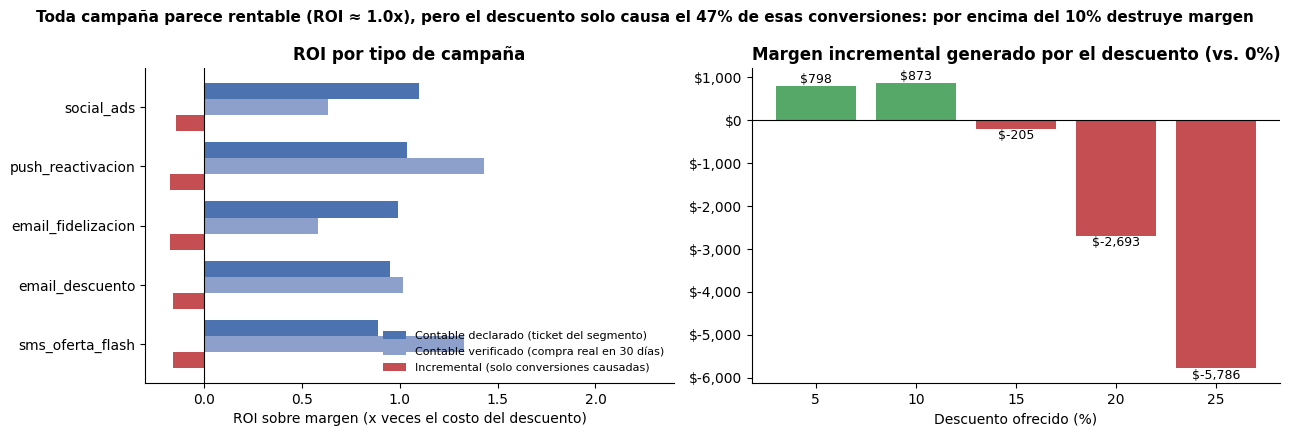

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
r = roi_tipo.drop('Total').join(inc_tipo.ROI_incremental)
y = np.arange(len(r)); h = 0.27
axes[0].barh(y - h, r.ROI_margen_decl, h, color='#4C72B0', label='Contable declarado (ticket del segmento)')
axes[0].barh(y, r.ROI_margen_verif, h, color='#8DA0CB', label='Contable verificado (compra real en 30 días)')
axes[0].barh(y + h, r.ROI_incremental, h, color='#C44E52', label='Incremental (solo conversiones causadas)')
axes[0].set_yticks(y, r.index); axes[0].invert_yaxis(); axes[0].axvline(0, c='k', lw=0.8); axes[0].set_xlim(-0.3, 2.4)
axes[0].set(xlabel='ROI sobre margen (x veces el costo del descuento)', title='ROI por tipo de campaña'); axes[0].legend(frameon=False, fontsize=8, loc='lower right')
c_ = ['#C44E52' if v < 0 else '#55A868' for v in inc_desc.margen_incremental]
axes[1].bar(inc_desc.index.astype(str), inc_desc.margen_incremental, color=c_)
for i, v in enumerate(inc_desc.margen_incremental):
    axes[1].text(i, v, f'${v:,.0f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=9)
axes[1].axhline(0, c='k', lw=0.8); axes[1].set(xlabel='Descuento ofrecido (%)', title='Margen incremental generado por el descuento (vs. 0%)')
axes[1].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'${x:,.0f}'))
fig.suptitle(f"Toda campaña parece rentable (ROI ≈ {roi_tipo.loc['Total','ROI_margen_decl']:.1f}x), pero el descuento solo causa el {inc_tipo.loc['Total','%_conv_incrementales']:.0%} de esas conversiones: "
             f"por encima del 10% destruye margen", fontsize=11,
             fontweight='bold')
plt.tight_layout(); plt.savefig(FIG / 'a4_roi_campanas.png', dpi=150); plt.show()

**Lectura del gráfico:** a la izquierda, la diferencia entre el ROI contable (azul, ~1x) y el incremental (rojo, negativo) es **el margen que se regala a quien habría comprado igual**. A la derecha, el punto de equilibrio está entre el 10 % y el 15 %: hasta el 10 % el descuento se paga solo; desde el 15 %, cada punto adicional compra conversiones que cuestan más margen del que generan.

### 4.2 Sensibilidad y verificación

In [14]:
# (a) Recalcular el ROI declarado del total por una vía independiente (agregados en vez de fila a fila).
cv = camp_r[conv]
tot_alt = ((cv.ticket_lista * (1 - cv.descuento_ofrecido)).sum() - (cv.ticket_lista * cv.descuento_ofrecido).sum()) / (cv.ticket_lista * cv.descuento_ofrecido).sum()
assert np.isclose(tot_alt, roi_tipo.loc['Total', 'ROI_ventas_decl'])
# (b) Las conversiones incrementales esperadas deben coincidir con las observadas: el modelo reproduce la tasa total.
assert np.isclose(camp_r.p_d.sum(), camp_r.convertido.sum(), rtol=0.01)
# (c) Sensibilidad al margen de lista (~29% promedio): el umbral de rentabilidad del descuento depende de él.
#     Escalar la conversión no sirve aquí (el resultado es lineal en p); el margen sí puede cambiar el signo.
sens = []
for f in [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]:
    ml = con_desc.margen_lista * f
    inc = con_desc.p_d * (ml - con_desc.ticket_lista * con_desc.descuento_ofrecido) - con_desc.p_0 * ml
    por_d = inc.groupby(con_desc.desc_pct).sum()
    sens.append({'margen_lista_%': (ml.sum() / con_desc.ticket_lista.sum()) * 100, 'margen_incremental_total': inc.sum(),
                 'mejor_descuento_%': por_d.idxmax(), 'margen_en_mejor_descuento': por_d.max(),
                 'descuentos_con_margen_negativo': ', '.join(f'{k}%' for k in por_d[por_d < 0].index) or 'ninguno'})
sens = pd.DataFrame(sens).set_index('margen_lista_%'); sens.to_csv(TAB / 'a4_sensibilidad_roi.csv')
display(sens.style.format({'margen_incremental_total': '${:,.0f}', 'margen_en_mejor_descuento': '${:,.0f}'}).format_index('{:.0f}%'))

# (d) Escenario para A5: tope de descuento del 10% (los envíos con 15–25% pasan a 10%), mismo modelo y mismos supuestos.
tope = con_desc.assign(desc_pct=con_desc.desc_pct.clip(upper=10), descuento_ofrecido=con_desc.descuento_ofrecido.clip(upper=0.10))
p_tope = m_cat.predict(tope)
esc = pd.DataFrame({'Actual': [con_desc.p_d.sum(), con_desc.costo_desc_esp.sum(), con_desc.margen_esp_d.sum()],
                    'Tope 10%': [p_tope.sum(), (p_tope * tope.ticket_lista * tope.descuento_ofrecido).sum(),
                                 (p_tope * (tope.margen_lista - tope.ticket_lista * tope.descuento_ofrecido)).sum()]},
                   index=['conversiones (24 m)', 'costo del descuento (24 m)', 'margen de campañas (24 m)'])
esc['diferencia'] = esc['Tope 10%'] - esc.Actual
esc['diferencia_6m'] = esc.diferencia / 4
esc['variación_%'] = esc.diferencia / esc.Actual
esc.to_csv(TAB / 'a4_escenario_tope_descuento.csv')
esc.style.format('${:,.0f}').format('{:,.0f}', subset=pd.IndexSlice['conversiones (24 m)', ['Actual', 'Tope 10%', 'diferencia', 'diferencia_6m']]).format('{:+.1%}', subset=['variación_%'])

,margen_incremental_total,mejor_descuento_%,margen_en_mejor_descuento,descuentos_con_margen_negativo
margen_lista_%,,,,
14%,"$-24,867",5,$-556,"5%, 10%, 15%, 20%, 25%"
22%,"$-15,940",5,$121,"10%, 15%, 20%, 25%"
29%,"$-7,013",10,$873,"15%, 20%, 25%"
36%,"$1,914",10,"$2,268","20%, 25%"
43%,"$10,841",15,"$4,020",25%
58%,"$28,695",15,"$8,245",ninguno


,Actual,Tope 10%,diferencia,diferencia_6m,variación_%
conversiones (24 m),721,623,-98,-24,-13.6%
costo del descuento (24 m),"$42,721","$20,989","$-21,731","$-5,433",-50.9%
margen de campañas (24 m),"$33,831","$45,168","$11,338","$2,834",+33.5%


**Lectura: el descuento óptimo depende del margen del producto. Con el margen actual (~29 %), el tope rentable es 10 %.**

- Las dos verificaciones independientes cuadran: el ROI total recalculado por agregados es idéntico, y el modelo reproduce las 797 conversiones observadas (margen de 1 %).
- **Sensibilidad al margen de lista:**
  - Con margen ≤ 14 % (el caso de **Electrónica**, con 6,3 % de margen neto según A2), **ningún** descuento es rentable.
  - Con 22 %, solo el 5 %.
  - Con el ~29 % actual, hasta 10 %.
  - Con 36 %, hasta 15 %.
  - Hace falta un margen de ~58 % para que el 25 % se pague.
- **Escenario "tope del 10 %"** (los envíos con 15–25 % pasan a 10 %):
  - Conversiones: **−14 %** (721 → 623 en 24 meses).
  - Costo del descuento: **−51 %** ($42,7K → $21,0K).
  - Margen generado por las campañas: **+34 %** ($33,8K → $45,2K), es decir, **+$11,3K en 24 meses ≈ +$2,8K cada 6 meses**.
- **Proporción:** el marketing es una fuga **pequeña** frente a devoluciones y descuentos en caja (A3: ~$543K en 6 meses). Su arreglo es barato y rápido, pero no es la palanca principal del relato.

## Resumen ejecutivo de A4

1. **Conversión:** la caída a la mitad se confirma (11,2 % → 6,9 %; 11,3 % → 5,6 % entre el 1T-2023 y el 4T-2024). No se debe a la apertura (estable en ~36 %), a la mezcla de segmentos ni a menos descuento: es un **escalón en la conversión de quien abre** al inicio de 2024. Las ventas totales no cayeron (A2), por lo que la métrica `convertido` **no refleja ventas** (solo el 22,5 % se verifica).
2. **Qué combinación rinde más:** **ninguna**. Tipo y canal no influyen (p = 0,58 y 0,75), y la interacción con segmento tampoco (p = 0,78). El retorno lo decide **a quién** se envía: Premium convierte 13,7 % e Inactivo 5,5 %, en cualquier formato.
3. **Efecto del descuento (controlando por segmento):** el descuento se asignó como al azar (experimento natural), así que el efecto es causal. **+1,3 pp de conversión por cada +5 pp de descuento**, igual en todos los segmentos, también en compras verificadas y con **techo en el 15–20 %** (pasar de 20 % a 25 % no suma).
4. **Segmento que no convierte: Inactivo.** Recibe el 14 % de los envíos, aporta el 8,5 % de las conversiones (18 envíos por conversión) y solo 2 compras verificadas. **Abre igual** que el resto, pero no compra. Las hipótesis de **CRM y devoluciones se rechazan**: no tiene más quejas, devuelve menos y ninguna variable de insatisfacción predice su no conversión. Es **baja intención** (61 % sin compras previas), no mala experiencia.
5. **ROI:** con la fórmula del enunciado todas las campañas rinden ~**4,9x sobre ventas**, pero solo **~1x sobre margen**, y ningún tipo se distingue. Medido de forma **incremental**, solo el 47 % de las conversiones las causa el descuento y el ROI es **−0,16x** (−$7,0K en 24 meses). El descuento solo crea margen **hasta el 10 %**.

→ **Para A5:** (a) **tope de descuento del 10 % en campañas**, que da +34 % de margen de campañas (≈ +$2,8K cada 6 meses) a cambio de −14 % de conversiones; (b) **reasignar frecuencia** de Inactivo hacia Premium y Nuevo (activación, A3); (c) **medir con grupo de control** (un 10 % sin campaña) y con **conversión verificada**, no con el flag `convertido`. Dimensión del problema: el marketing es una fuga menor frente a devoluciones y descuentos en caja; su valor en el relato es mostrar que **el descuento sin control** es el mismo patrón en caja (A2) y en campañas (A4).